# Анализ открытых данных кофейни в Индонезии

In [10]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)

In [12]:
SRC = Path('Transactions.csv') 
print('Файл существует:', SRC.exists())

df = pd.read_csv(SRC, encoding='utf-8-sig')
df.columns = [c.strip() for c in df.columns]
print('Размер:', df.shape)
df.head()

Файл существует: True
Размер: (53820, 11)


,Outlet,Date,Time,NetSales,Tax,TotalAmount,ReceiptNumber,Items,TotalItem,PaymentMethod,UseLoyaltyCard
0,SHOP001,2025-01-02,07:01:05,20720.721,2279.279,23000,SHOP001JAN2500001,Basic Latte (Ice Arabica),1,BCA,0
1,SHOP001,2025-01-02,07:04:11,18018.018,1981.982,20000,SHOP001JAN2500002,BLACK (Houseblend),1,BCA,0
2,SHOP002,2025-01-02,07:10:46,39639.640,4360.360,44000,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",2,Cash,0
3,SHOP002,2025-01-02,07:14:25,36036.036,3963.964,40000,SHOP002JAN2500002,"BLACK (Arabica), Americano (Hot Arabica)",2,Cash,0
4,SHOP002,2025-01-02,07:23:05,36036.036,3963.964,40000,SHOP002JAN2500003,"WHITE (Arabica), Susu Oat",2,Cash,0


### Подготовка данных

In [13]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df['Time'] = pd.to_datetime(df['Time'], format='%H:%M:%S', errors='coerce').dt.time

for col in ['NetSales', 'Tax', 'TotalAmount', 'TotalItem', 'UseLoyaltyCard']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.dropna(subset=['Date', 'TotalAmount', 'ReceiptNumber']).copy()

df['Hour']       = pd.to_datetime(df['Time'].astype(str), format='%H:%M:%S').dt.hour
df['Weekday']    = df['Date'].dt.day_name()
df['WeekdayNum'] = df['Date'].dt.weekday
df['Month']      = df['Date'].dt.to_period('M').astype(str)
df['Week']       = df['Date'].dt.to_period('W').astype(str)

print('Диапазон:', df['Date'].min().date(), '—', df['Date'].max().date())
print('Точки:', df['Outlet'].unique().tolist())
print('Строк:', len(df))
df.head()

Диапазон: 2025-01-02 — 2025-09-30
Точки: ['SHOP001', 'SHOP002', 'SHOP003']
Строк: 53820


,Outlet,Date,Time,NetSales,Tax,TotalAmount,ReceiptNumber,Items,TotalItem,PaymentMethod,UseLoyaltyCard,Hour,Weekday,WeekdayNum,Month,Week
0,SHOP001,2025-01-02,07:01:05,20720.721,2279.279,23000,SHOP001JAN2500001,Basic Latte (Ice Arabica),1,BCA,0,7,Thursday,3,2025-01,2024-12-30/2025-01-05
1,SHOP001,2025-01-02,07:04:11,18018.018,1981.982,20000,SHOP001JAN2500002,BLACK (Houseblend),1,BCA,0,7,Thursday,3,2025-01,2024-12-30/2025-01-05
2,SHOP002,2025-01-02,07:10:46,39639.640,4360.360,44000,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",2,Cash,0,7,Thursday,3,2025-01,2024-12-30/2025-01-05
3,SHOP002,2025-01-02,07:14:25,36036.036,3963.964,40000,SHOP002JAN2500002,"BLACK (Arabica), Americano (Hot Arabica)",2,Cash,0,7,Thursday,3,2025-01,2024-12-30/2025-01-05
4,SHOP002,2025-01-02,07:23:05,36036.036,3963.964,40000,SHOP002JAN2500003,"WHITE (Arabica), Susu Oat",2,Cash,0,7,Thursday,3,2025-01,2024-12-30/2025-01-05


In [14]:
zero = df[df['TotalAmount'] == 0]
print(f'Нулевых чеков: {len(zero)} ({len(zero)/len(df)*100:.2f}%)')
print('Из них с картой лояльности:', int(zero['UseLoyaltyCard'].sum()))
zero.head()

Нулевых чеков: 1733 (3.22%)
Из них с картой лояльности: 1733


,Outlet,Date,Time,NetSales,Tax,TotalAmount,ReceiptNumber,Items,TotalItem,PaymentMethod,UseLoyaltyCard,Hour,Weekday,WeekdayNum,Month,Week
31,SHOP001,2025-01-02,10:37:45,0.0,0.0,0,SHOP001JAN2500013,Cappuccino (Hot Houseblend),1,Cash,1,10,Thursday,3,2025-01,2024-12-30/2025-01-05
37,SHOP002,2025-01-02,10:59:44,0.0,0.0,0,SHOP002JAN2500016,Friendly Coffee (Gedhe),1,Cash,1,10,Thursday,3,2025-01,2024-12-30/2025-01-05
78,SHOP001,2025-01-02,13:58:16,0.0,0.0,0,SHOP001JAN2500038,Cappuccino (Ice Houseblend),1,Cash,1,13,Thursday,3,2025-01,2024-12-30/2025-01-05
85,SHOP002,2025-01-02,14:35:33,0.0,0.0,0,SHOP002JAN2500025,Not Tiramisu Latte (Gedhe),1,Cash,1,14,Thursday,3,2025-01,2024-12-30/2025-01-05
86,SHOP003,2025-01-02,14:38:03,0.0,0.0,0,SHOP003JAN2500019,Waffle,1,Cash,1,14,Thursday,3,2025-01,2024-12-30/2025-01-05


### Общие KPI

In [15]:
kpi = {
    'Выручка (TotalAmount)': df['TotalAmount'].sum(),
    'Net Sales':              df['NetSales'].sum(),
    'Налог':                  df['Tax'].sum(),
    'Чеков':                  df['ReceiptNumber'].nunique(),
    'Позиций продано':        int(df['TotalItem'].sum()),
    'Средний чек (AOV)':      df['TotalAmount'].mean(),
    'Позиций в чеке (ср.)':   df['TotalItem'].mean(),
    'Доля лояльности, %':     df['UseLoyaltyCard'].mean() * 100,
}
pd.Series(kpi).to_frame('Значение')

,Значение
Выручка (TotalAmount),1.315276e+09
Net Sales,1.184933e+09
Налог,1.303427e+08
Чеков,5.382000e+04
Позиций продано,6.197300e+04
Средний чек (AOV),2.443842e+04
Позиций в чеке (ср.),1.151486e+00
"Доля лояльности, %",3.219993e+00


### Выручка по точкам

In [16]:
outlet_df = df.groupby('Outlet').agg(
    Revenue=('TotalAmount', 'sum'),
    NetSales=('NetSales', 'sum'),
    Receipts=('ReceiptNumber', 'nunique'),
    Items=('TotalItem', 'sum'),
    AOV=('TotalAmount', 'mean'),
    AvgItems=('TotalItem', 'mean'),
    LoyaltyShare=('UseLoyaltyCard', 'mean'),
).reset_index()
outlet_df['LoyaltyShare'] *= 100
outlet_df = outlet_df.sort_values('Revenue', ascending=False)
outlet_df

,Outlet,Revenue,NetSales,Receipts,Items,AOV,AvgItems,LoyaltyShare
0,SHOP001,644108000,5.802775e+08,26250,30249,24537.447619,1.152343,2.914286
2,SHOP003,409504000,3.689225e+08,16753,19341,24443.622038,1.154480,3.354623
1,SHOP002,261664000,2.357333e+08,10817,12383,24190.071184,1.144772,3.753351


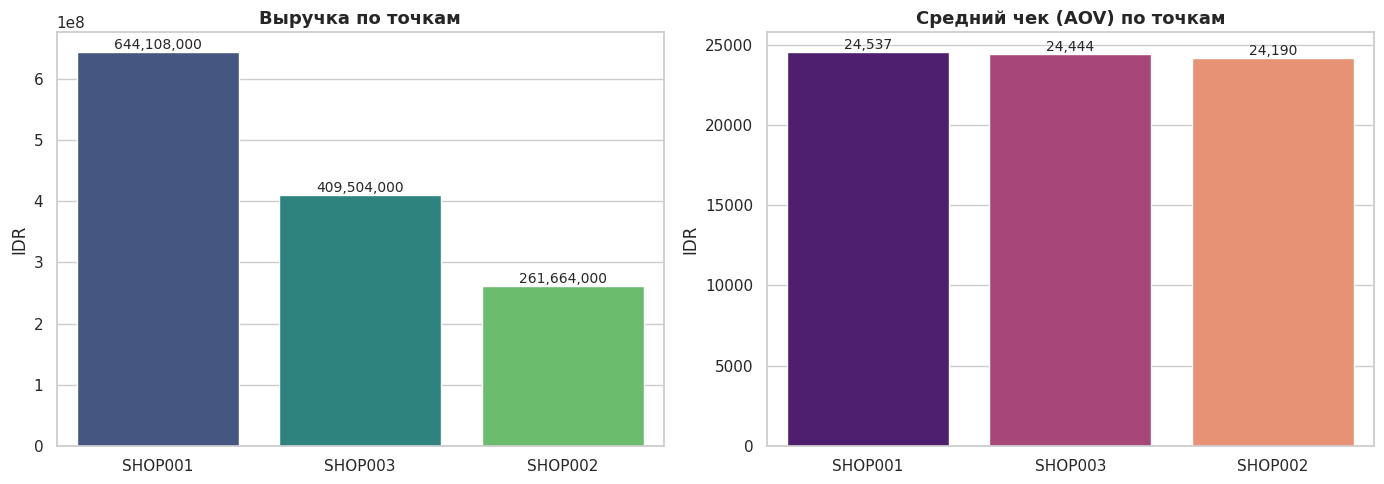

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=outlet_df, x='Outlet', y='Revenue', ax=axes[0], palette='viridis')
for i, v in enumerate(outlet_df['Revenue']):
    axes[0].text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=10)
axes[0].set_title('Выручка по точкам')
axes[0].set_ylabel('IDR'); axes[0].set_xlabel('')

sns.barplot(data=outlet_df, x='Outlet', y='AOV', ax=axes[1], palette='magma')
for i, v in enumerate(outlet_df['AOV']):
    axes[1].text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=10)
axes[1].set_title('Средний чек (AOV) по точкам')
axes[1].set_ylabel('IDR'); axes[1].set_xlabel('')

plt.tight_layout(); plt.show()

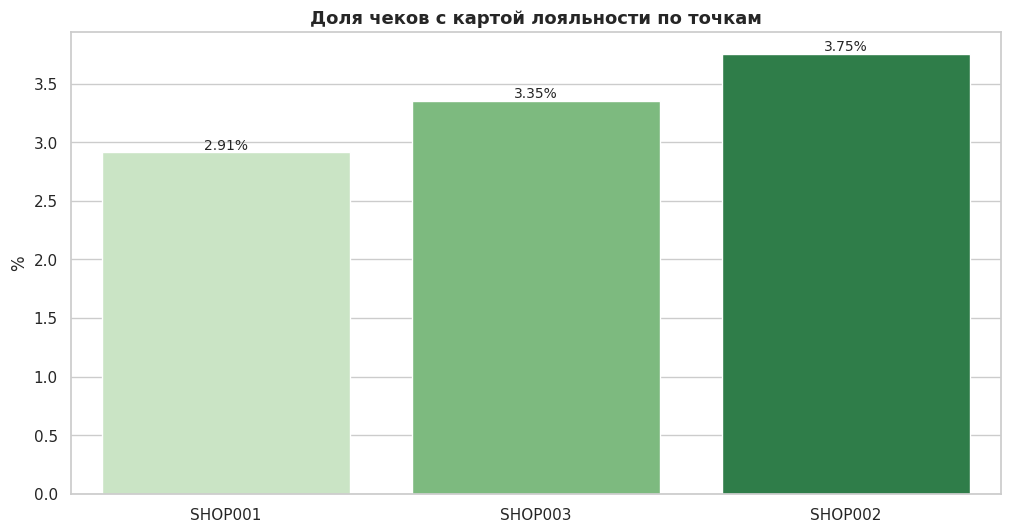

In [18]:
fig, ax = plt.subplots()
sns.barplot(data=outlet_df, x='Outlet', y='LoyaltyShare', ax=ax, palette='Greens')
for i, v in enumerate(outlet_df['LoyaltyShare']):
    ax.text(i, v, f'{v:.2f}%', ha='center', va='bottom', fontsize=10)
ax.set_title('Доля чеков с картой лояльности по точкам')
ax.set_ylabel('%'); ax.set_xlabel('')
plt.show()

1) SHOP001 - флагман ~96 чеков в день.

2) SHOP002 - проблемная точка ~40 чеков в день - убыточный уровень для аренды+персонала в большинстве локаций.

3) AOV одинаковый во всех трёх точках (24,2–24,5k). Значит цены и меню идентичны, разница только в трафике.

4) Лояльность растёт обратно трафику: чем меньше клиентов, тем выше доля лояльных, то есть в SHOP002 удержание работает, но новых клиентов нет.

Итог: SHOP002 требует либо релокации, либо агрессивного локального маркетинга, либо сокращения издержек (например, режим работы только в пиковые часы).

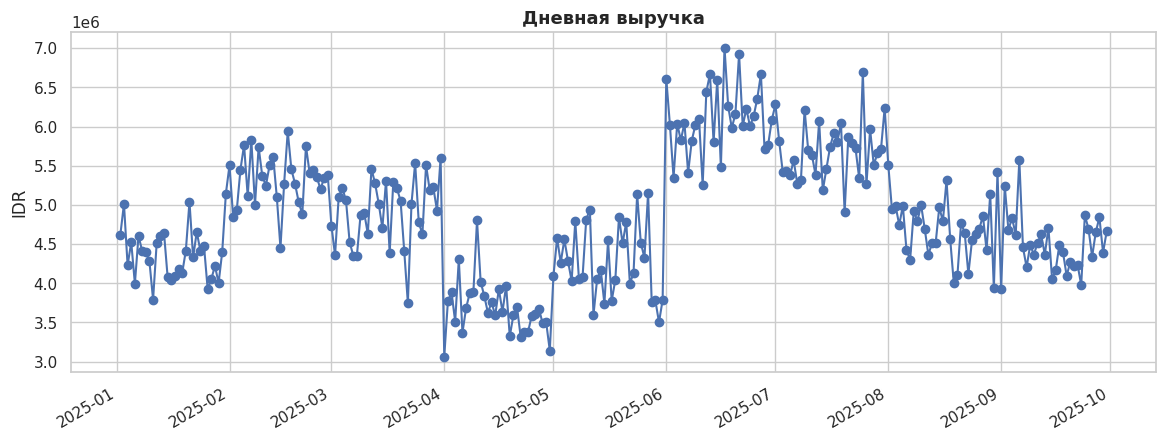

In [19]:
daily = df.groupby('Date').agg(
    Revenue=('TotalAmount', 'sum'),
    Receipts=('ReceiptNumber', 'nunique'),
).reset_index()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily['Date'], daily['Revenue'], marker='o', linewidth=1.5)
ax.set_title('Дневная выручка')
ax.set_ylabel('IDR'); ax.set_xlabel('')
fig.autofmt_xdate()
plt.show()

### Месячная динамика

In [20]:
monthly = df.groupby('Month').agg(
    Revenue=('TotalAmount', 'sum'),
    Receipts=('ReceiptNumber', 'nunique'),
    AOV=('TotalAmount', 'mean'),
).reset_index()
monthly

,Month,Revenue,Receipts,AOV
0,2025-01,131233000,5372,24429.076694
1,2025-02,149180000,6124,24359.895493
2,2025-03,152385000,6255,24362.110312
3,2025-04,110195000,4439,24824.284749
4,2025-05,132639000,5426,24445.079248
5,2025-06,182769000,7530,24272.111554
6,2025-07,176286000,7176,24566.053512
7,2025-08,145624000,5972,24384.460817
8,2025-09,134965000,5526,24423.633731


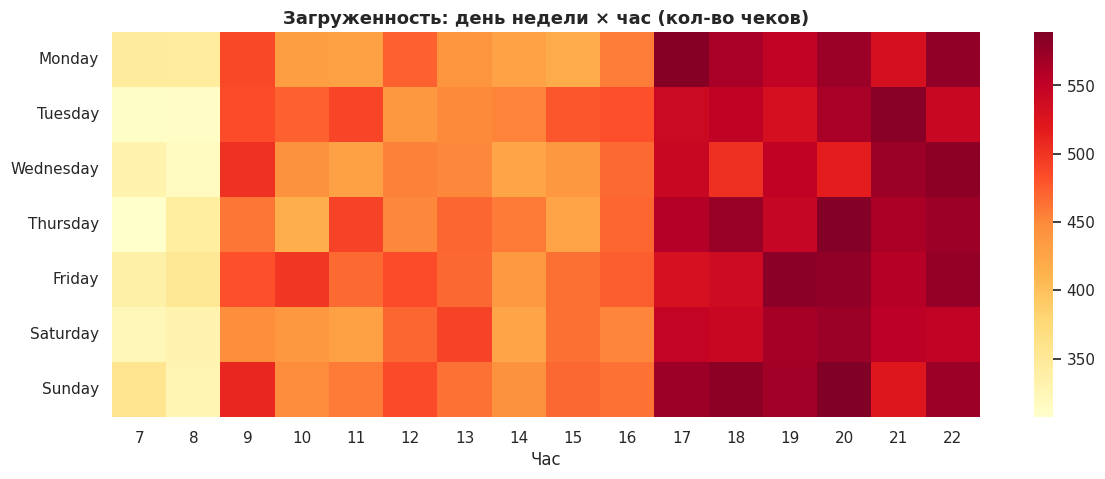

In [21]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

pivot = (df.groupby(['Weekday','Hour'])['ReceiptNumber']
           .nunique().unstack(fill_value=0)
           .reindex(order))

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot, cmap='YlOrRd', ax=ax)
ax.set_title('Загруженность: день недели × час (кол-во чеков)')
ax.set_xlabel('Час'); ax.set_ylabel('')
plt.show()

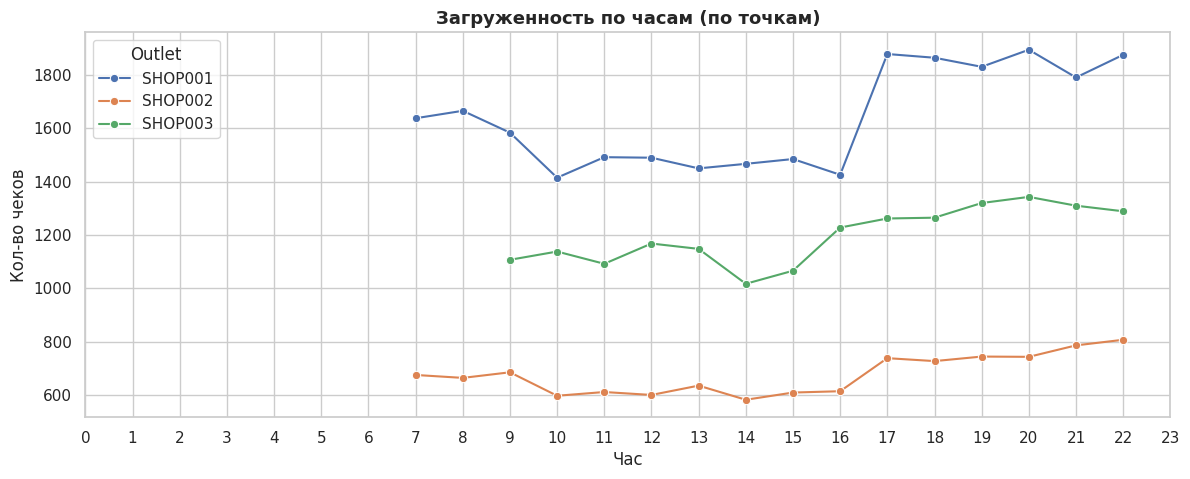

In [22]:
hourly = df.groupby(['Outlet','Hour'])['ReceiptNumber'].nunique().reset_index()

fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=hourly, x='Hour', y='ReceiptNumber', hue='Outlet', marker='o', ax=ax)
ax.set_title('Загруженность по часам (по точкам)')
ax.set_xlabel('Час'); ax.set_ylabel('Кол-во чеков')
ax.set_xticks(range(0, 24))
plt.show()

### Дни недели

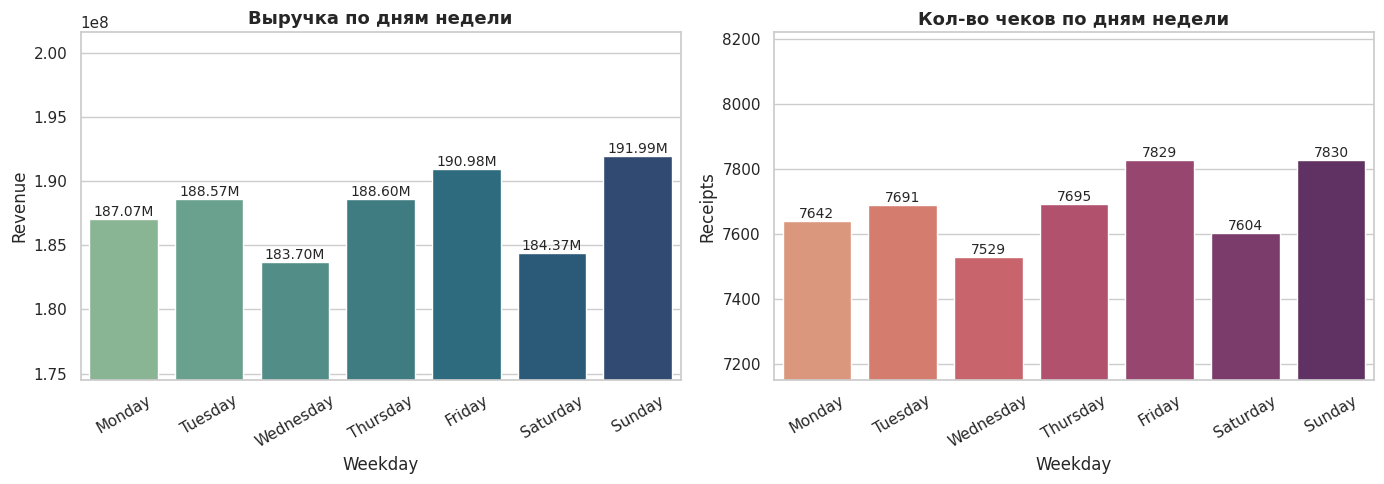

,Weekday,Revenue,Receipts,AOV
0,Monday,187068000,7642,24478.932217
1,Tuesday,188575000,7691,24518.918216
2,Wednesday,183699000,7529,24398.857750
3,Thursday,188604000,7695,24509.941520
4,Friday,190978000,7829,24393.664580
5,Saturday,184367000,7604,24246.054708
6,Sunday,191985000,7830,24519.157088


In [41]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

wd = df.groupby('Weekday').agg(
    Revenue=('TotalAmount', 'sum'),
    Receipts=('ReceiptNumber', 'nunique'),
    AOV=('TotalAmount', 'mean'),
).reindex(order).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Выручка
sns.barplot(data=wd, x='Weekday', y='Revenue', ax=axes[0], palette='crest')
for i, v in enumerate(wd['Revenue']):
    axes[0].text(i, v, f'{v/1e6:.2f}M', ha='center', va='bottom', fontsize=10)
axes[0].set_title('Выручка по дням недели')
axes[0].set_ylim(wd['Revenue'].min() * 0.95, wd['Revenue'].max() * 1.05)
axes[0].tick_params(axis='x', rotation=30)

# Кол-во чеков
sns.barplot(data=wd, x='Weekday', y='Receipts', ax=axes[1], palette='flare')
for i, v in enumerate(wd['Receipts']):
    axes[1].text(i, v, f'{v}', ha='center', va='bottom', fontsize=10)
axes[1].set_title('Кол-во чеков по дням недели')
axes[1].set_ylim(wd['Receipts'].min() * 0.95, wd['Receipts'].max() * 1.05)
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout(); plt.show()
wd

In [34]:
tmp = df.copy()
tmp['ItemsList'] = tmp['Items'].fillna('').astype(str).apply(
    lambda s: [x.strip() for x in s.split(',') if x.strip()]
)
exploded = tmp.explode('ItemsList').rename(columns={'ItemsList':'Item'})
exploded = exploded[exploded['Item'].notna() & (exploded['Item'] != '')]

print('Всего строк-позиций:', len(exploded))
exploded[['ReceiptNumber','Outlet','Item','TotalAmount']].head(10)

Всего строк-позиций: 61973


,ReceiptNumber,Outlet,Item,TotalAmount
0,SHOP001JAN2500001,SHOP001,Basic Latte (Ice Arabica),23000
1,SHOP001JAN2500002,SHOP001,BLACK (Houseblend),20000
2,SHOP002JAN2500001,SHOP002,Friendly Coffee (Hot),44000
2,SHOP002JAN2500001,SHOP002,Shakencano,44000
3,SHOP002JAN2500002,SHOP002,BLACK (Arabica),40000
3,SHOP002JAN2500002,SHOP002,Americano (Hot Arabica),40000
4,SHOP002JAN2500003,SHOP002,WHITE (Arabica),40000
4,SHOP002JAN2500003,SHOP002,Susu Oat,40000
5,SHOP001JAN2500003,SHOP001,Americano (Hot Houseblend),20000
6,SHOP002JAN2500004,SHOP002,Banana Bread (Chocolate),12000


### Категоризация позиций

In [35]:
def categorize(name):
    n = str(name).lower()
    if any(k in n for k in ['latte','cappuccino','moca','americano','espresso',
                            'black','white','cold brew','matchapresso',
                            'shakencano','butterscotch','hazelnut','burnt sugar']):
        return 'Coffee'
    if any(k in n for k in ['tea','jasmine','chamomile','thai','matcha']):
        return 'Tea'
    if any(k in n for k in ['jus','lemon','apple','berry','liquid','summer',
                            'sunset','moody','forbidden']):
        return 'Cold drinks / Juice'
    if any(k in n for k in ['cake','croffle','waffle','banana bread','donat',
                            'nutella','pisang','chocolate (','pie','cookie']):
        return 'Food / Dessert'
    if any(k in n for k in ['extra shot','upgrade beans','air mineral',
                            'susu oat','oat']):
        return 'Extras'
    return 'Other'

exploded['Category'] = exploded['Item'].apply(categorize)
exploded['Category'].value_counts()

Category
Coffee                 30895
Food / Dessert          7254
Tea                     7230
Other                   6659
Cold drinks / Juice     6603
Extras                  3332
Name: count, dtype: int64

### Топ-10 позиций по выручке

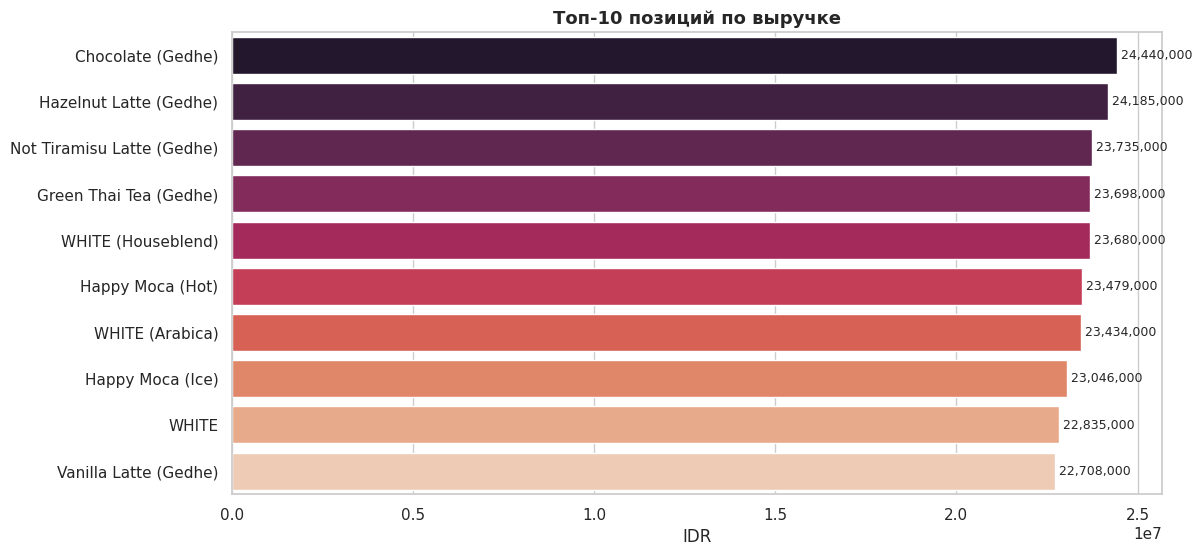

,Item,Revenue,Sales
31,Chocolate (Gedhe),24440000,700
58,Hazelnut Latte (Gedhe),24185000,692
74,Not Tiramisu Latte (Gedhe),23735000,698
53,Green Thai Tea (Gedhe),23698000,687
92,WHITE (Houseblend),23680000,688
55,Happy Moca (Hot),23479000,680
91,WHITE (Arabica),23434000,679
56,Happy Moca (Ice),23046000,664
90,WHITE,22835000,658
89,Vanilla Latte (Gedhe),22708000,663


In [36]:
top = (exploded.groupby('Item')
       .agg(Revenue=('TotalAmount','sum'),
            Sales=('ReceiptNumber','count'))
       .reset_index()
       .sort_values('Revenue', ascending=False)
       .head(10))

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=top, y='Item', x='Revenue', ax=ax, palette='rocket')
for i, v in enumerate(top['Revenue']):
    ax.text(v, i, f' {v:,.0f}', va='center', fontsize=9)
ax.set_title('Топ-10 позиций по выручке')
ax.set_xlabel('IDR'); ax.set_ylabel('')
plt.show()
top

1) Топ-10 дают 18% выручки, каждая позиция ~660–700 продаж за 9 месяцев. Это ~2,5 продажи в день на позицию на всю сеть, то есть очень низкая концентрация.

2) Нет "звезд", спрос размазан по меню, что усложняет управление запасами.

3) Все топ-позиции имеют размер Gedhe (большой), то есть клиенты готовы платить за объём, но не за разнообразие.

### Категории: выручка и продажи

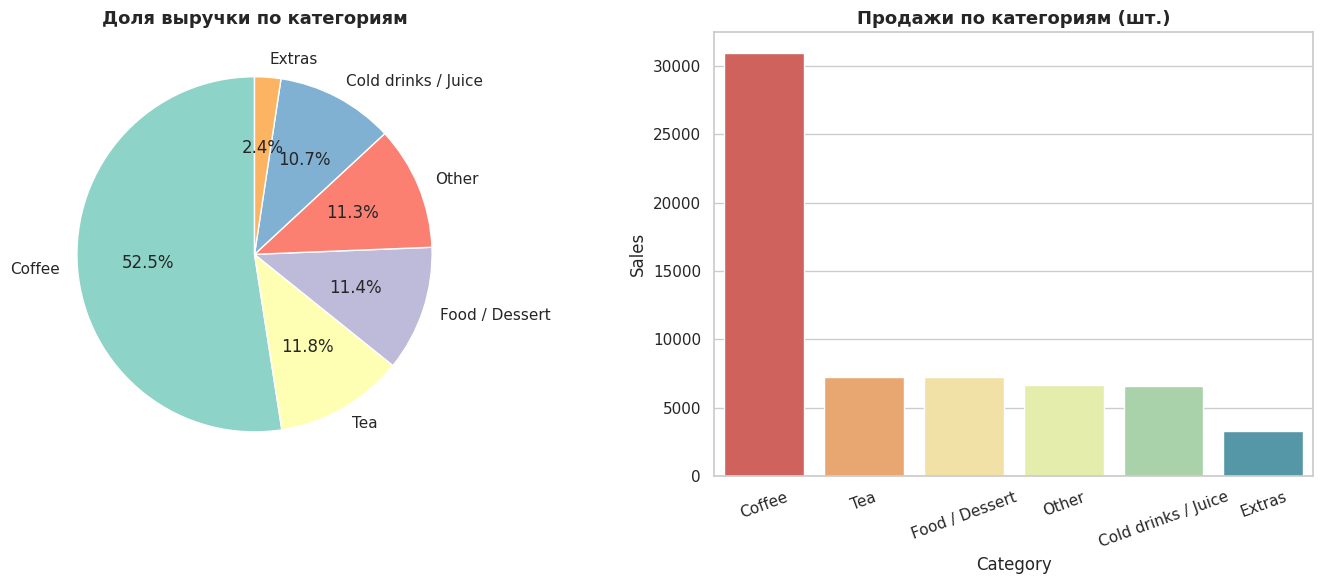

,Category,Revenue,Sales,ShareRevenue
0,Coffee,878088000,30895,52.461124
5,Tea,196904000,7230,11.763975
3,Food / Dessert,190966000,7254,11.409211
4,Other,188548000,6659,11.264748
1,Cold drinks / Juice,179364000,6603,10.716052
2,Extras,39918000,3332,2.384890


In [37]:
cat = (exploded.groupby('Category')
       .agg(Revenue=('TotalAmount','sum'),
            Sales=('ReceiptNumber','count'))
       .reset_index()
       .sort_values('Revenue', ascending=False))
cat['ShareRevenue'] = cat['Revenue'] / cat['Revenue'].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].pie(cat['Revenue'], labels=cat['Category'], autopct='%1.1f%%',
            startangle=90, colors=sns.color_palette('Set3', len(cat)))
axes[0].set_title('Доля выручки по категориям')

sns.barplot(data=cat, x='Category', y='Sales', ax=axes[1], palette='Spectral')
axes[1].set_title('Продажи по категориям (шт.)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout(); plt.show()
cat

1) Кофе = 52,5% норма для кофейни.

2) Food / Dessert = 11,4% низко. Именно десерты дают +AOV.

3) Other = 11,3% большая доля неопознанных позиций (проблема категоризации).

4) Extras = 2,4% почти не продаются. Упущенная маржа.

### Способы оплаты

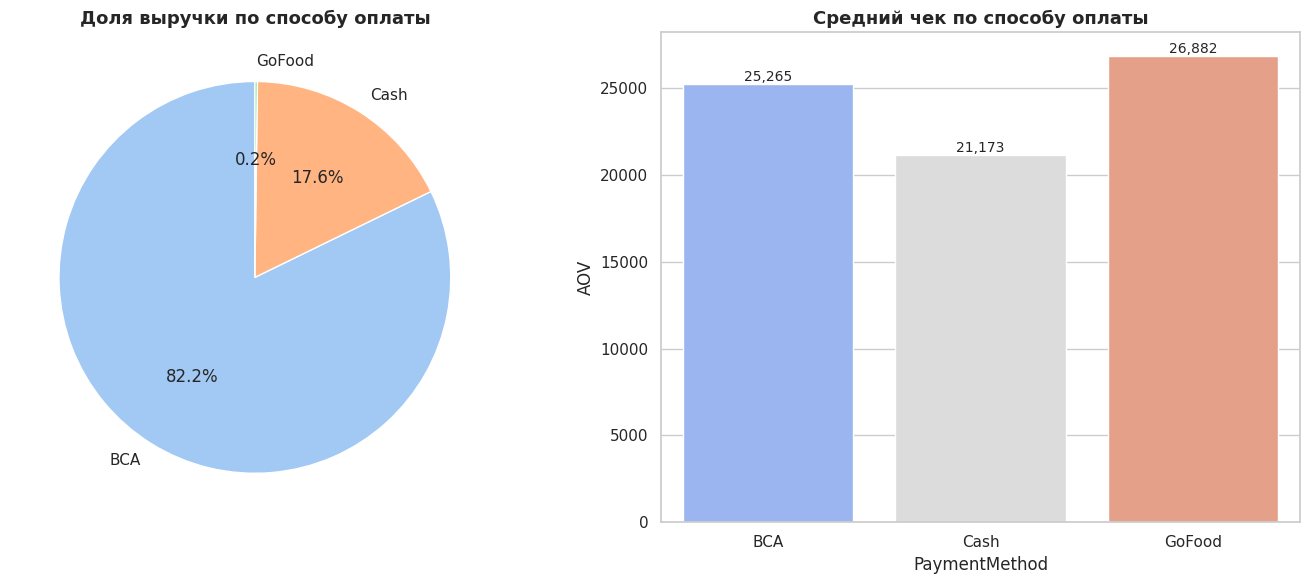

,PaymentMethod,Revenue,Receipts,AOV,ShareRevenue
0,BCA,1081473000,42805,25265.109216,82.224035
1,Cash,231061000,10913,21173.004673,17.567492
2,GoFood,2742000,102,26882.352941,0.208473


In [38]:
pay = df.groupby('PaymentMethod').agg(
    Revenue=('TotalAmount','sum'),
    Receipts=('ReceiptNumber','nunique'),
    AOV=('TotalAmount','mean'),
).reset_index()
pay['ShareRevenue'] = pay['Revenue'] / pay['Revenue'].sum() * 100
pay = pay.sort_values('Revenue', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].pie(pay['Revenue'], labels=pay['PaymentMethod'], autopct='%1.1f%%',
            startangle=90, colors=sns.color_palette('pastel'))
axes[0].set_title('Доля выручки по способу оплаты')

sns.barplot(data=pay, x='PaymentMethod', y='AOV', ax=axes[1], palette='coolwarm')
for i, v in enumerate(pay['AOV']):
    axes[1].text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=10)
axes[1].set_title('Средний чек по способу оплаты')

plt.tight_layout(); plt.show()
pay

1) 2% выручки - это безнал (BCA), следовательно, платёжеспособная городская аудитория.

2) Cash-чеки дешевле на 16% (21,2k vs 25,3k), то есть случайные клиенты.

3) GoFood = 0.2% канал не развит. За 9 месяцев всего 102 заказа. Это аномалия для Индонезии, где GoFood - стандарт. Либо точка не подключена, либо не продвигается.

Возможность: при доведении GoFood до 5% выручки +65 млн IDR за 9 месяцев.

### Топ-10 позиций в каждой точке

In [39]:
top_by_outlet = (exploded.groupby(['Outlet','Item'])
                 .agg(Revenue=('TotalAmount','sum'),
                      Sales=('ReceiptNumber','count'))
                 .reset_index()
                 .sort_values(['Outlet','Revenue'], ascending=[True, False])
                 .groupby('Outlet').head(10))
top_by_outlet

,Outlet,Item,Revenue,Sales
58,SHOP001,Hazelnut Latte (Gedhe),12263000,349
74,SHOP001,Not Tiramisu Latte (Gedhe),12216000,349
91,SHOP001,WHITE (Arabica),12159000,346
92,SHOP001,WHITE (Houseblend),11704000,335
18,SHOP001,Biru (Gedhe),11453000,332
55,SHOP001,Happy Moca (Hot),11415000,326
53,SHOP001,Green Thai Tea (Gedhe),11268000,322
89,SHOP001,Vanilla Latte (Gedhe),11202000,324
70,SHOP001,Matchapresso (Gedhe),11157000,320
6,SHOP001,Apple Pie Latte (Gedhe),11141000,319


### Структура чеков

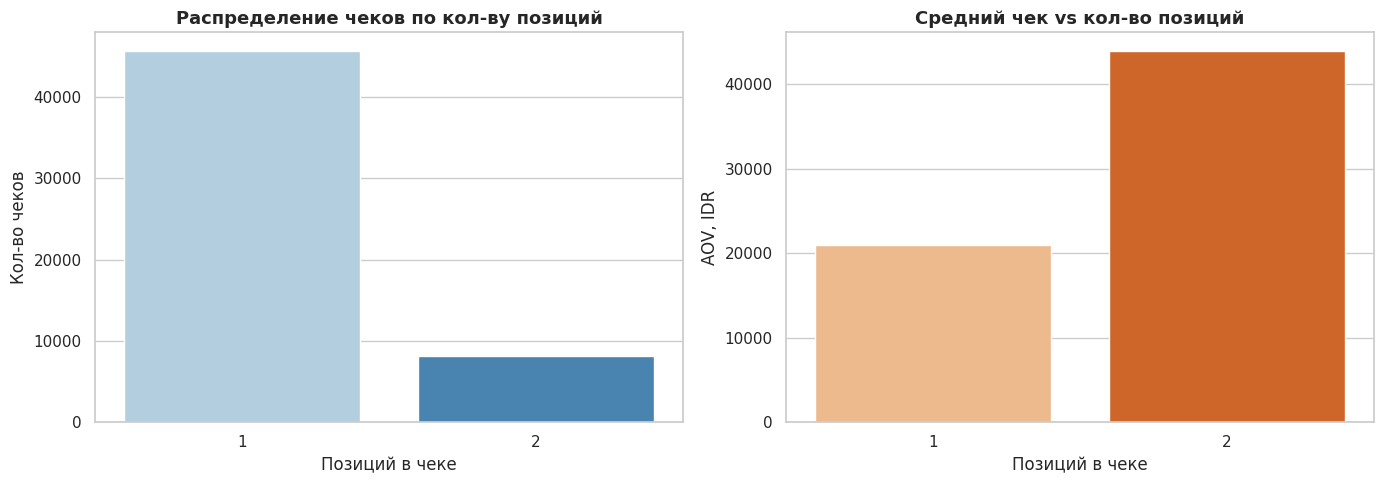

,TotalItem,Checks,Revenue,AOV
0,1,45667,956764000,20950.883570
1,2,8153,358512000,43973.016068


In [40]:
basket = df.groupby('TotalItem').agg(
    Checks=('ReceiptNumber','nunique'),
    Revenue=('TotalAmount','sum'),
    AOV=('TotalAmount','mean'),
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=basket, x='TotalItem', y='Checks', ax=axes[0], palette='Blues')
axes[0].set_title('Распределение чеков по кол-ву позиций')
axes[0].set_xlabel('Позиций в чеке'); axes[0].set_ylabel('Кол-во чеков')

sns.barplot(data=basket, x='TotalItem', y='AOV', ax=axes[1], palette='Oranges')
axes[1].set_title('Средний чек vs кол-во позиций')
axes[1].set_xlabel('Позиций в чеке'); axes[1].set_ylabel('AOV, IDR')

plt.tight_layout(); plt.show()
basket

1) 85% чеков - одна позиция.

2) Клиент с 2 позициями платит в 2,1 раза больше (44k vs 21k).

3) Чеков с 3+ позициями нет вообще - это нетипично даже для кофейни.

3) 15% чеков с 2 позициями дают 27% выручки - непропорционально много.

Итог: если поднять долю чеков с 2 позициями с 15% до 25% (за 9 месяцев):

- Дополнительно 5 382 чека × 23 000 IDR = +124 млн IDR за 9 месяцев

- +9,4% к общей выручке без единого нового клиента

# Выводы

### Сильные стороны
- Стабильный спрос без сезонных провалов по дням недели.

- Высокая доля безнала (82%) - платёжеспособная аудитория.

- Стандартизированный AOV (~24k) - легко масштабировать и прогнозировать.

- Кофе = устойчивое ядро (52,5%).

- SHOP001 — здоровая кофейня (~96 чеков/день).

### Слабые стороны
- 85% чеков - одна позиция - колоссальный недобор выручки.

- Лояльность 3,2% - программа не работает.

- GoFood 0,2% - канал не развит (при огромном рынке доставки в Индонезии).

- SHOP002 в 2,4 раза слабее SHOP001 по трафику - риск закрытия.

- Food / Dessert = 11,4% - низко для точки с посадочными местами.

- Extras = 2,4% - допы не продаются.

- Отсутствие сезонного роста - за 9 месяцев нет месячного тренда.

### Стратегия:
Сеть работает стабильно. Основной рычаг не привлечение новых клиентов, а увеличение среднего чека. Критическая структурная проблема: нет чеков с 3+ позициями. Это значит, что клиенты приходят за одним напитком и не рассматривают кофейню как место посидеть. Решение:
- пересмотреть формат (посадочные места, атмосфера)

- внедрить комбо-меню

- ввести акции со скидкой при покупке кофе

- пересмотреть ценообразование extras